# Exercice 4 : un CNN sur Fashion-MNIST

In [1]:
import tensorflow as tf

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
print(x_train.shape, y_train.shape)        # (60000, 28, 28) (60000,)

classes = ["T-shirt/top", "Pantalon", "Pull", "Robe", "Manteau",
           "Sandale", "Chemise", "Sneaker", "Sac", "Bottine"]

(60000, 28, 28) (60000,)


In [2]:
X_train = x_train
X_test = x_test

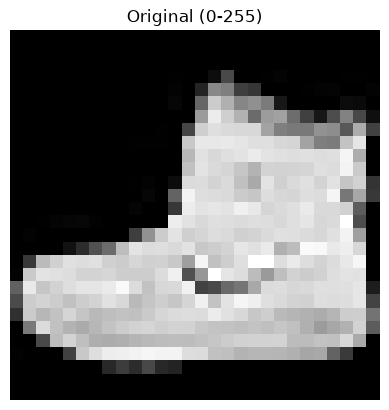

Formes finales : (60000, 28, 28, 1) (10000, 28, 28, 1)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 3, 3, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 576)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.7636 - loss: 0.6519 - val_accuracy: 0.8475 - val_loss: 0.4103
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8572 - loss: 0.3991 - val_accuracy: 0.8785 - val_loss: 0.3334
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8771 - loss: 0.3431 - val_accuracy: 0.8832 - val_loss: 0.3104
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8885 - loss: 0.3116 - val_accuracy: 0.8873 - val_loss: 0.2991
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8973 - loss: 0.2856 - val_accuracy: 0.8963 - val_loss: 0.2754
313/313 - 1s - 4ms/step - accuracy: 0.8944 - loss: 0.2850

Précision sur le test : 89.44%
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


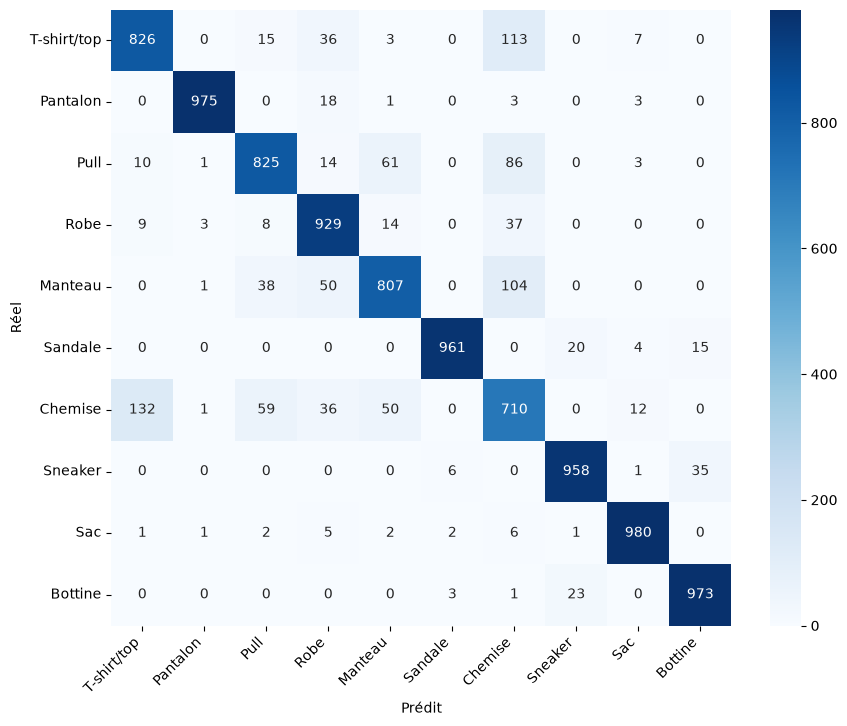

              precision    recall  f1-score   support

 T-shirt/top       0.84      0.83      0.84      1000
    Pantalon       0.99      0.97      0.98      1000
        Pull       0.87      0.82      0.85      1000
        Robe       0.85      0.93      0.89      1000
     Manteau       0.86      0.81      0.83      1000
     Sandale       0.99      0.96      0.97      1000
     Chemise       0.67      0.71      0.69      1000
     Sneaker       0.96      0.96      0.96      1000
         Sac       0.97      0.98      0.98      1000
     Bottine       0.95      0.97      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.90      0.89      0.89     10000
weighted avg       0.90      0.89      0.89     10000



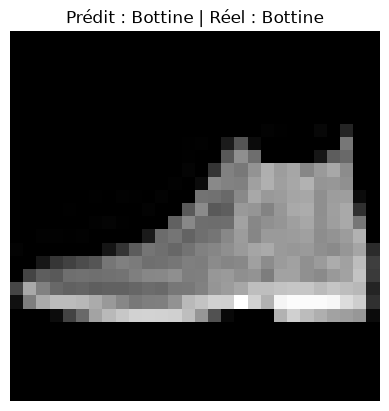

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import datasets, layers, models, Input
from sklearn.metrics import confusion_matrix, classification_report

img = X_train[0]

plt.imshow(img, cmap="gray")
plt.title("Original (0-255)")
plt.axis("off")
plt.show()

X_train = np.expand_dims(X_train.astype("float32") / 255.0, -1)
X_test = np.expand_dims(X_test.astype("float32") / 255.0, -1)

print("Formes finales :", X_train.shape, X_test.shape)

model = models.Sequential([
    Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

model.summary()

history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

loss, acc = model.evaluate(X_test, y_test, verbose=2)

print(f"\nPrécision sur le test : {acc * 100:.2f}%")

y_pred = np.argmax(model.predict(X_test), axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)

plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.show()

print(classification_report(y_test, y_pred, target_names=classes))

plt.imshow(X_test[0].squeeze(), cmap="gray")
plt.title(f"Prédit : {classes[y_pred[0]]} | Réel : {classes[y_test[0]]}")
plt.axis("off")
plt.show()